# SC4020 Project 2 Task 1: Analysis of Drug–Target Datasets

## Step 1: Load the data and check it

This notebook expects a `data/` folder next to it, containing `davis/` and `kiba/` from the DeepDTA repository.

In [41]:
# Run once to install the libraries (skip if already installed)
%pip install pandas numpy matplotlib seaborn scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [42]:
import json
import pickle
from collections import OrderedDict
from pathlib import Path

import numpy as np
import pandas as pd

DATA_DIR = Path("data")

### Load ligands, targets and the score matrix

`ligands_can.txt` and `proteins.txt` are JSON dictionaries (ID → SMILES / sequence). `Y` is a pickled matrix whose rows follow the ligand order and columns follow the target order, so the dictionary order must be kept.

In [43]:
def load_dataset(name):
    folder = DATA_DIR / name
    with open(folder / "ligands_can.txt") as f:
        ligands = json.load(f, object_pairs_hook=OrderedDict)
    with open(folder / "proteins.txt") as f:
        proteins = json.load(f, object_pairs_hook=OrderedDict)
    with open(folder / "Y", "rb") as f:
        Y = np.asarray(pickle.load(f, encoding="latin1"), dtype=float)  
    return ligands, proteins, Y

davis_ligands, davis_proteins, davis_Y = load_dataset("davis")
kiba_ligands, kiba_proteins, kiba_Y = load_dataset("kiba")

### Sanity checks against the project description

Expected: 68 × 442 with 30056 observed pairs for DAVIS. 
2111 × 229 with 118254 observed pairs for KIBA.

In [44]:
def summarise(name, ligands, proteins, Y):
    observed = np.isfinite(Y).sum()
    return {
        "dataset": name,
        "ligands": len(ligands),
        "targets": len(proteins),
        "matrix shape": Y.shape,
        "observed pairs": int(observed),
        "missing pairs": int(Y.size - observed),
        "sparsity": round(1 - observed / Y.size, 4),
        "unique SMILES": len(set(ligands.values())),
        "unique sequences": len(set(proteins.values())),
        "min score": np.nanmin(Y),
        "max score": np.nanmax(Y),
    }

pd.DataFrame([
    summarise("DAVIS (Kd, nM)", davis_ligands, davis_proteins, davis_Y),
    summarise("KIBA", kiba_ligands, kiba_proteins, kiba_Y),
]).set_index("dataset").T

dataset,"DAVIS (Kd, nM)",KIBA
ligands,68,2111
targets,442,229
matrix shape,"(68, 442)","(2111, 229)"
observed pairs,30056,118254
missing pairs,0,365165
sparsity,0.0,0.7554
unique SMILES,68,2068
unique sequences,379,229
min score,0.016,0.0
max score,10000.0,17.200179


### Example records (long format)

One row per observed ligand–target pair, which is the format the later tasks will use.

In [45]:
def to_long(ligands, proteins, Y):
    lig_ids, lig_smiles = list(ligands.keys()), list(ligands.values())
    tgt_ids, tgt_seqs = list(proteins.keys()), list(proteins.values())
    rows, cols = np.where(np.isfinite(Y))
    return pd.DataFrame({
        "ligand_id": [lig_ids[i] for i in rows],
        "target_id": [tgt_ids[j] for j in cols],
        "smiles": [lig_smiles[i] for i in rows],
        "sequence": [tgt_seqs[j] for j in cols],
        "score": Y[rows, cols],
    })

davis_df = to_long(davis_ligands, davis_proteins, davis_Y)
kiba_df = to_long(kiba_ligands, kiba_proteins, kiba_Y)

def preview(df, n=5):
    # shorten long strings so the table is readable
    out = df.head(n).copy()
    out["smiles"] = out["smiles"].str.slice(0, 30) + "…"
    out["sequence"] = out["sequence"].str.slice(0, 30) + "…"
    return out

display(preview(davis_df))
display(preview(kiba_df))

,ligand_id,target_id,smiles,sequence,score
0,11314340,AAK1,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=…,MKKFFDSRREQGGSGLGSGSSGGGGSTSGL…,43.0
1,11314340,ABL1(E255K),CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=…,PFWKILNPLLERGTYYYFMGQQPGKVLGDQ…,10000.0
2,11314340,ABL1(F317I),CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=…,PFWKILNPLLERGTYYYFMGQQPGKVLGDQ…,10000.0
3,11314340,ABL1(F317I)p,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=…,PFWKILNPLLERGTYYYFMGQQPGKVLGDQ…,10000.0
4,11314340,ABL1(F317L),CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=…,PFWKILNPLLERGTYYYFMGQQPGKVLGDQ…,10000.0


,ligand_id,target_id,smiles,sequence,score
0,CHEMBL1087421,O00141,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=…,MTVKTEAAKGTLTYSRMRGMVAILIAFMKQ…,11.1
1,CHEMBL1087421,O14920,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=…,MSWSPSLTTQTCGAWEMKERLGTGGFGNVI…,11.1
2,CHEMBL1087421,O15111,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=…,MERPPGLRPGAGGPWEMRERLGTGGFGNVC…,11.1
3,CHEMBL1087421,P00533,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=…,MRPSGTAGAALLALLAALCPASRALEEKKV…,11.1
4,CHEMBL1087421,P04626,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=…,MELAALCRWGLLLALLPPGAASTQVCTGTD…,11.1


## Step 2: Data cleaning

1. **Validity:** Drop non-finite scores. DAVIS also requires $K_d > 0$ 
2. **Scale:** convert DAVIS to $\mathrm{p}K_d = 9 - \log_{10}(K_d)$ with $K_d$ in nM. KIBA scores are used as supplied (higher = stronger).
3. **Abnormal values are flagged instead of being removed:** DAVIS screening-limit records ($K_d = 10000$ nM, i.e. $\mathrm{p}K_d = 5$) and KIBA extreme scores.
4. **Deduplication:** pairs with the same ligand SMILES and target sequence are merged and their scores are averaged (in $\mathrm{p}K_d$ space for DAVIS).

In [46]:
DAVIS_LIMIT_PKD = 5.0   

def validate(df, name):
    n0 = len(df)
    df = df[np.isfinite(df["score"])].copy()
    if name == "DAVIS":
        df = df[df["score"] > 0].copy()          # Kd must be positive
        df["kd_nM"] = df["score"]
        df["score"] = 9 - np.log10(df["kd_nM"])  
    print(f"{name}: {n0} records -> {len(df)} valid ({n0 - len(df)} removed)")
    return df

davis_valid = validate(davis_df, "DAVIS")
kiba_valid = validate(kiba_df, "KIBA")

DAVIS: 30056 records -> 30056 valid (0 removed)
KIBA: 118254 records -> 118254 valid (0 removed)


### Abnormal values (kept, but flagged)

In [47]:
davis_valid["at_screening_limit"] = np.isclose(davis_valid["score"], DAVIS_LIMIT_PKD)

q1, q3 = kiba_valid["score"].quantile([0.25, 0.75])
iqr = q3 - q1
kiba_valid["extreme_low"] = kiba_valid["score"] < q1 - 3 * iqr
kiba_valid["extreme_high"] = kiba_valid["score"] > q3 + 3 * iqr

abnormal = pd.DataFrame({
    "records": [
        davis_valid["at_screening_limit"].sum(),
        (kiba_valid["score"] == 0).sum(),
        kiba_valid["extreme_low"].sum(),
        kiba_valid["extreme_high"].sum(),
    ],
}, index=[
    "DAVIS at screening limit (pKd = 5)",
    "KIBA score exactly 0",
    f"KIBA extreme low (< Q1 - 3 IQR = {q1 - 3*iqr:.2f})",
    f"KIBA extreme high (> Q3 + 3 IQR = {q3 + 3*iqr:.2f})",
])
abnormal["% of dataset"] = [
    100 * abnormal["records"].iloc[0] / len(davis_valid),
    *(100 * abnormal["records"].iloc[1:] / len(kiba_valid)),
]
abnormal.round(2)

,records,% of dataset
DAVIS at screening limit (pKd = 5),20931,69.64
KIBA score exactly 0,1,0.00
KIBA extreme low (< Q1 - 3 IQR = 9.03),20,0.02
KIBA extreme high (> Q3 + 3 IQR = 14.10),2943,2.49


### Deduplication by SMILES + sequence

Some IDs share identical inputs: in DAVIS several mutant targets (e.g. `BRAF` and `BRAF(V600E)`) have the same supplied sequence, and in KIBA some ligand IDs share a canonical SMILES (stereoisomers). Since models will see SMILES and sequences, such pairs are indistinguishable and their scores are averaged. Each merged entity keeps a representative ID (the first in file order) and the full list of original IDs.

In [48]:
def deduplicate(df, extra_flags=()):
    
    lig = (df.groupby("smiles", sort=False)["ligand_id"]
             .agg(lambda s: list(dict.fromkeys(s))).rename("ligand_ids").reset_index())
    lig["ligand_key"] = lig["ligand_ids"].str[0]
    tgt = (df.groupby("sequence", sort=False)["target_id"]
             .agg(lambda s: list(dict.fromkeys(s))).rename("target_ids").reset_index())
    tgt["target_key"] = tgt["target_ids"].str[0]

    df = df.merge(lig[["smiles", "ligand_key"]], on="smiles").merge(tgt[["sequence", "target_key"]], on="sequence")
    agg = {"score": ["mean", "std", "min", "max", "count"]}
    agg.update({flag: "mean" for flag in extra_flags})   
    pairs = df.groupby(["ligand_key", "target_key"], sort=False).agg(agg)
    pairs.columns = ["score", "score_std", "score_min", "score_max", "n_merged", *[f"frac_{f}" for f in extra_flags]]
    pairs = pairs.reset_index()

    lig["ligand_ids"] = lig["ligand_ids"].str.join("|")
    tgt["target_ids"] = tgt["target_ids"].str.join("|")
    return pairs, lig, tgt

davis_pairs, davis_lig, davis_tgt = deduplicate(davis_valid, extra_flags=["at_screening_limit"])
kiba_pairs, kiba_lig, kiba_tgt = deduplicate(kiba_valid, extra_flags=["extreme_low", "extreme_high"])

### Original vs. deduplicated counts

In [49]:
def counts(raw, pairs, lig, tgt):
    return {
        ("Ligands", "original IDs"): raw["ligand_id"].nunique(),
        ("Ligands", "deduplicated"): len(lig),
        ("Targets", "original IDs"): raw["target_id"].nunique(),
        ("Targets", "deduplicated"): len(tgt),
        ("Observed pairs", "original"): len(raw),
        ("Observed pairs", "deduplicated"): len(pairs),
        ("Observed pairs", "merged groups (n > 1)"): int((pairs["n_merged"] > 1).sum()),
        ("Matrix", "sparsity after dedup"): round(1 - len(pairs) / (len(lig) * len(tgt)), 4),
    }

count_table = pd.DataFrame({
    "DAVIS": counts(davis_df, davis_pairs, davis_lig, davis_tgt),
    "KIBA": counts(kiba_df, kiba_pairs, kiba_lig, kiba_tgt),
}, dtype=object)
count_table

DAVIS      KIBA
Ligands        original IDs              68.0    2111.0
               deduplicated              68.0    2068.0
Targets        original IDs             442.0     229.0
               deduplicated             379.0     229.0
Observed pairs original               30056.0  118254.0
               deduplicated           25772.0  117657.0
               merged groups (n > 1)   1224.0     473.0
Matrix         sparsity after dedup       0.0    0.7516

### How much do merged duplicates disagree?

A large spread means the averaged score hides real differences (e.g. a mutant binding very differently from the wild type).

In [50]:
def disagreement(pairs):
    m = pairs[pairs["n_merged"] > 1]
    spread = m["score_max"] - m["score_min"]
    return {
        "merged groups": len(m),
        "mean within-group std": round(m["score_std"].mean(), 3),
        "max spread (max - min)": round(spread.max(), 3),
        "groups with spread > 1": int((spread > 1).sum()),
    }

display(pd.DataFrame({"DAVIS (pKd)": disagreement(davis_pairs), "KIBA": disagreement(kiba_pairs)}))

# merged DAVIS target groups
davis_tgt[davis_tgt["target_ids"].str.contains("|", regex=False)][["target_key", "target_ids"]].head(10)

,DAVIS (pKd),KIBA
merged groups,1224.000,473.000
mean within-group std,0.248,0.243
max spread (max - min),4.745,2.778
groups with spread > 1,260.000,61.000


,target_key,target_ids
1,ABL1(E255K),ABL1(E255K)|ABL1(F317I)|ABL1(F317I)p|ABL1(F317...
30,BRAF,BRAF|BRAF(V600E)
52,CDK4-cyclinD1,CDK4-cyclinD1|CDK4-cyclinD3
96,EGFR,EGFR|EGFR(E746A750del)|EGFR(G719C)|EGFR(G719S)...
126,FGFR3,FGFR3|FGFR3(G697C)
130,FLT3,FLT3|FLT3(D835H)|FLT3(D835Y)|FLT3(ITD)|FLT3(K6...
159,JAK1(JH1domain-catalytic),JAK1(JH1domain-catalytic)|JAK1(JH2domain-pseud...
165,KIT,KIT|KIT(A829P)|KIT(D816H)|KIT(D816V)|KIT(L576P...
173,LRRK2,LRRK2|LRRK2(G2019S)
202,MET,MET|MET(M1250T)|MET(Y1235D)


### Save the cleaned data for Tasks 2 and 3

Pairs files hold `ligand_key, target_key, score`. The lookup files map each key to its SMILES or sequence and original IDs. Sequences are stored once per target to keep files small.

In [51]:
CLEAN_DIR = DATA_DIR / "clean"
CLEAN_DIR.mkdir(exist_ok=True)

for name, pairs, lig, tgt in [("davis", davis_pairs, davis_lig, davis_tgt),
                              ("kiba", kiba_pairs, kiba_lig, kiba_tgt)]:
    pairs.to_csv(CLEAN_DIR / f"{name}_pairs.csv", index=False)
    lig[["ligand_key", "ligand_ids", "smiles"]].to_csv(CLEAN_DIR / f"{name}_ligands.csv", index=False)
    tgt[["target_key", "target_ids", "sequence"]].to_csv(CLEAN_DIR / f"{name}_targets.csv", index=False)

sorted(p.name for p in CLEAN_DIR.iterdir())

['davis_ligands.csv',
 'davis_pairs.csv',
 'davis_targets.csv',
 'kiba_ligands.csv',
 'kiba_pairs.csv',
 'kiba_targets.csv']

## Step 3: Visualisation

All plots use the cleaned, deduplicated data from Step 2. Figures are also saved to `figures/` for the report.

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

def to_matrix(pairs):
    # ligand x target matrix while unmeasured pairs are set to NaN
    return pairs.pivot(index="ligand_key", columns="target_key", values="score")

davis_M = to_matrix(davis_pairs)
kiba_M = to_matrix(kiba_pairs)
davis_M.shape, kiba_M.shape

((68, 379), (2068, 229))

### Heatmaps

Rows and columns are sorted so structure is visible: DAVIS by mean $\mathrm{p}K_d$ (strong binders top-left) and KIBA by number of observations (densely measured ligands/targets top-left). Missing entries are drawn in grey.

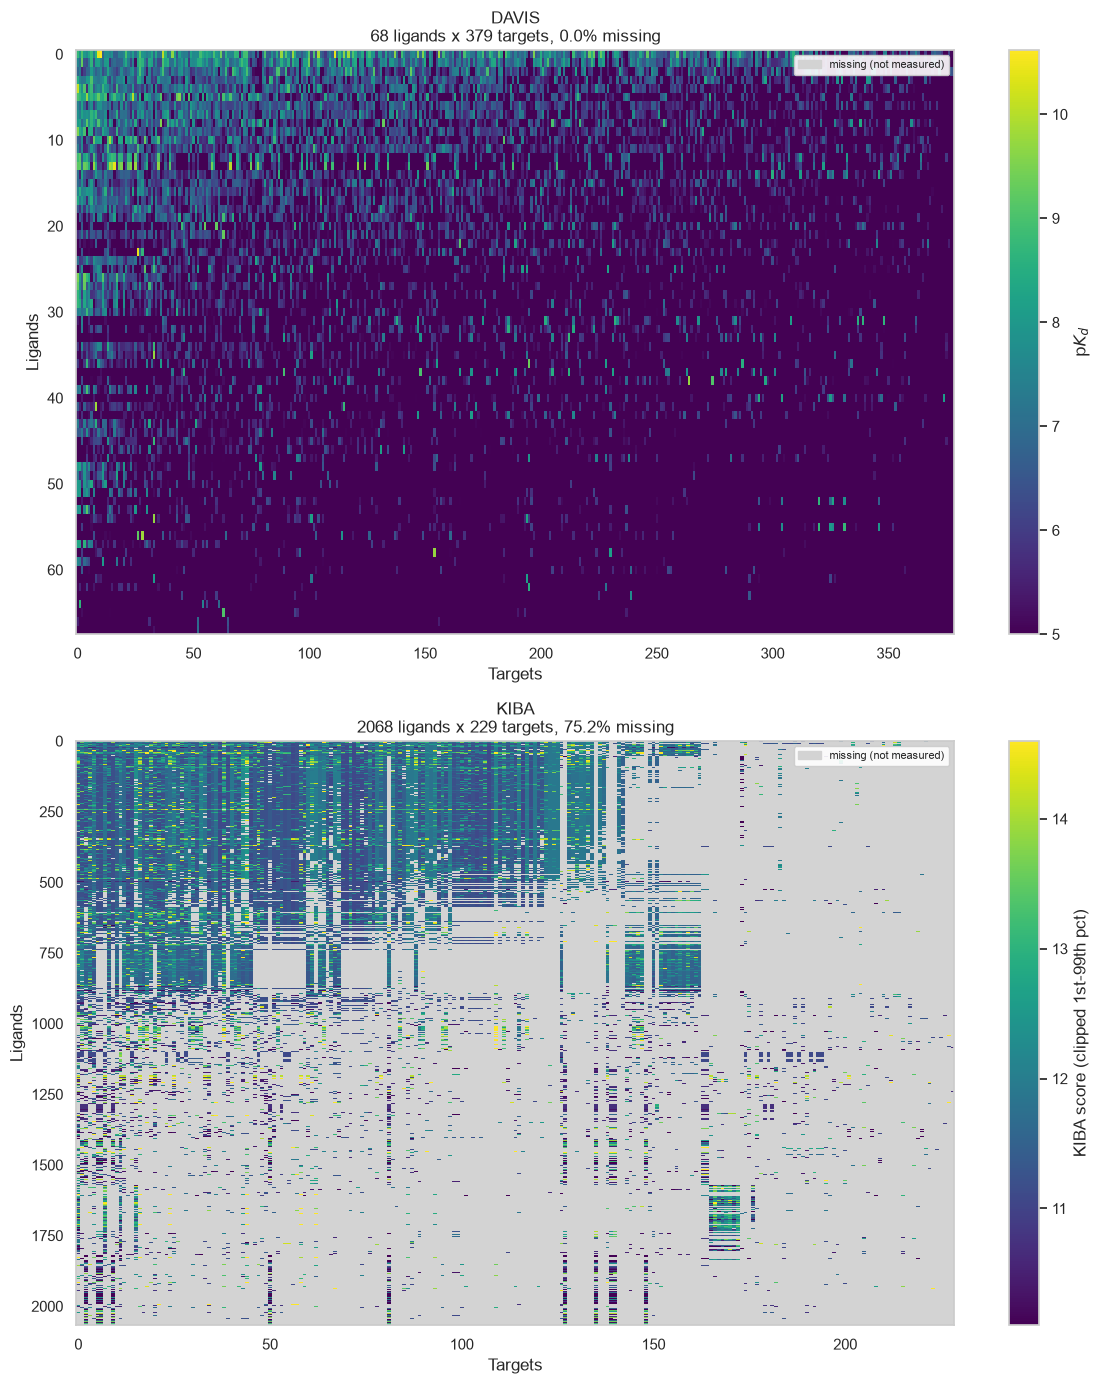

In [53]:
def plot_heatmap(M, title, label, sort_by="mean", clip=None, ax=None):
    key = M.mean if sort_by == "mean" else M.count
    M = M.loc[key(axis=1).sort_values(ascending=False).index,
              key(axis=0).sort_values(ascending=False).index]
    vmin, vmax = (np.nanpercentile(M.values, clip) if clip else (np.nanmin(M.values), np.nanmax(M.values)))
    cmap = plt.get_cmap("viridis").copy()
    cmap.set_bad("lightgrey")
    im = ax.imshow(np.ma.masked_invalid(M.values), aspect="auto", cmap=cmap,
                   vmin=vmin, vmax=vmax, interpolation="nearest")
    plt.colorbar(im, ax=ax, label=label)
    missing = M.isna().values.mean()
    ax.set_title(f"{title}\n{M.shape[0]} ligands x {M.shape[1]} targets, {missing:.1%} missing")
    ax.grid(False)
    ax.set_xlabel("Targets")
    ax.set_ylabel("Ligands")
    ax.legend(handles=[Patch(color="lightgrey", label="missing (not measured)")],
              loc="upper right", fontsize=8, framealpha=0.9)

fig, axes = plt.subplots(2, 1, figsize=(12, 14))
plot_heatmap(davis_M, "DAVIS", r"$\mathrm{p}K_d$", sort_by="mean", ax=axes[0])
plot_heatmap(kiba_M, "KIBA", "KIBA score (clipped 1st-99th pct)", sort_by="count", clip=(1, 99), ax=axes[1])
plt.tight_layout()
plt.savefig(FIG_DIR / "heatmaps.png", dpi=200)
plt.show()

### Score distributions (KDE)

`cut=0` stops the KDE from extending past the observed range (there are no DAVIS values below $\mathrm{p}K_d = 5$). For DAVIS, the dashed curve shows the distribution without the screening-limit records so the shape of the measurable binders is visible.

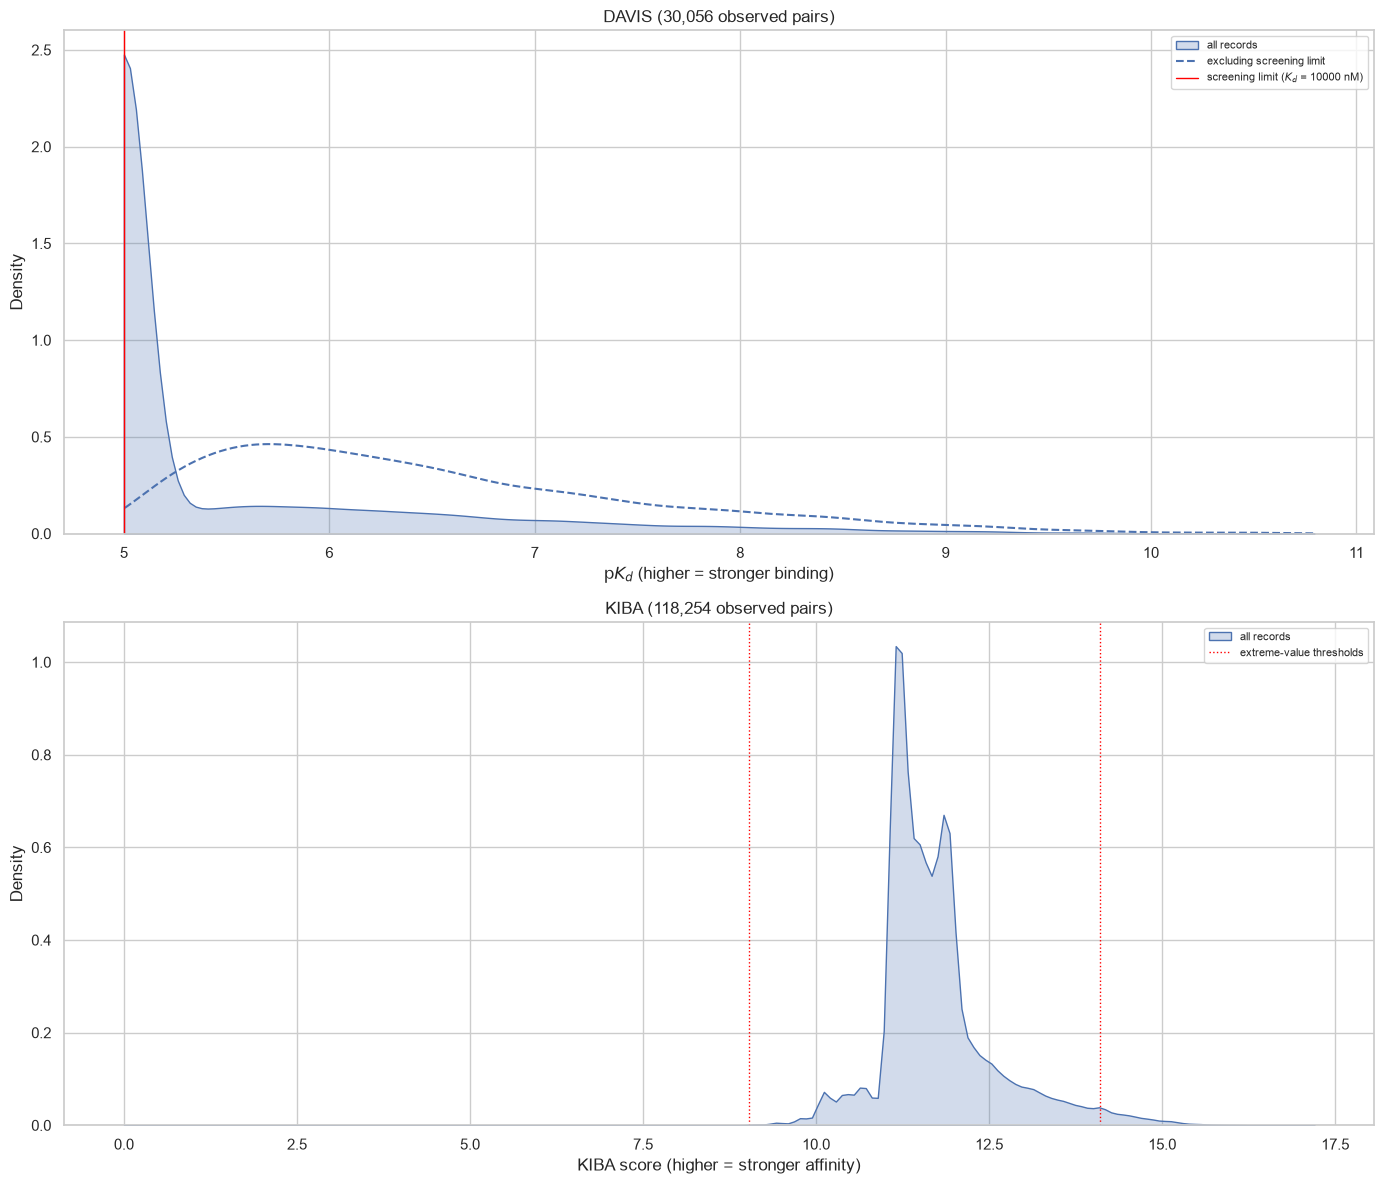

,DAVIS (pKd),KIBA
count,30056.000,118254.000
mean,5.452,11.720
std,0.895,0.837
min,5.000,0.000
25%,5.000,11.200
50%,5.000,11.500
75%,5.523,11.924
max,10.796,17.200


In [54]:
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

sns.kdeplot(davis_valid["score"], ax=axes[0], fill=True, cut=0, label="all records")
sns.kdeplot(davis_valid.loc[~davis_valid["at_screening_limit"], "score"], ax=axes[0],
            cut=0, linestyle="--", label="excluding screening limit")
axes[0].axvline(DAVIS_LIMIT_PKD, color="red", linewidth=1, label=r"screening limit ($K_d$ = 10000 nM)")
axes[0].set_xlabel(r"$\mathrm{p}K_d$ (higher = stronger binding)")
axes[0].set_ylabel("Density")
axes[0].set_title(f"DAVIS ({len(davis_valid):,} observed pairs)")
axes[0].legend(fontsize=8)

sns.kdeplot(kiba_valid["score"], ax=axes[1], fill=True, cut=0, label="all records")
axes[1].axvline(q1 - 3 * iqr, color="red", linewidth=1, linestyle=":", label="extreme-value thresholds")
axes[1].axvline(q3 + 3 * iqr, color="red", linewidth=1, linestyle=":")
axes[1].set_xlabel("KIBA score (higher = stronger affinity)")
axes[1].set_ylabel("Density")
axes[1].set_title(f"KIBA ({len(kiba_valid):,} observed pairs)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIG_DIR / "kde_distributions.png", dpi=200)
plt.show()

pd.DataFrame({"DAVIS (pKd)": davis_valid["score"].describe(),
              "KIBA": kiba_valid["score"].describe()}).round(3)

## Step 4: Further analysis of ligands and targets

### 4a. How evenly are ligands and targets measured?

DAVIS is complete, so every ligand has 379 measured targets. In KIBA the number of observations per ligand/target varies a lot. This matters for collaborative filtering in Task 2: a ligand with few observations has little information for finding similar neighbours.

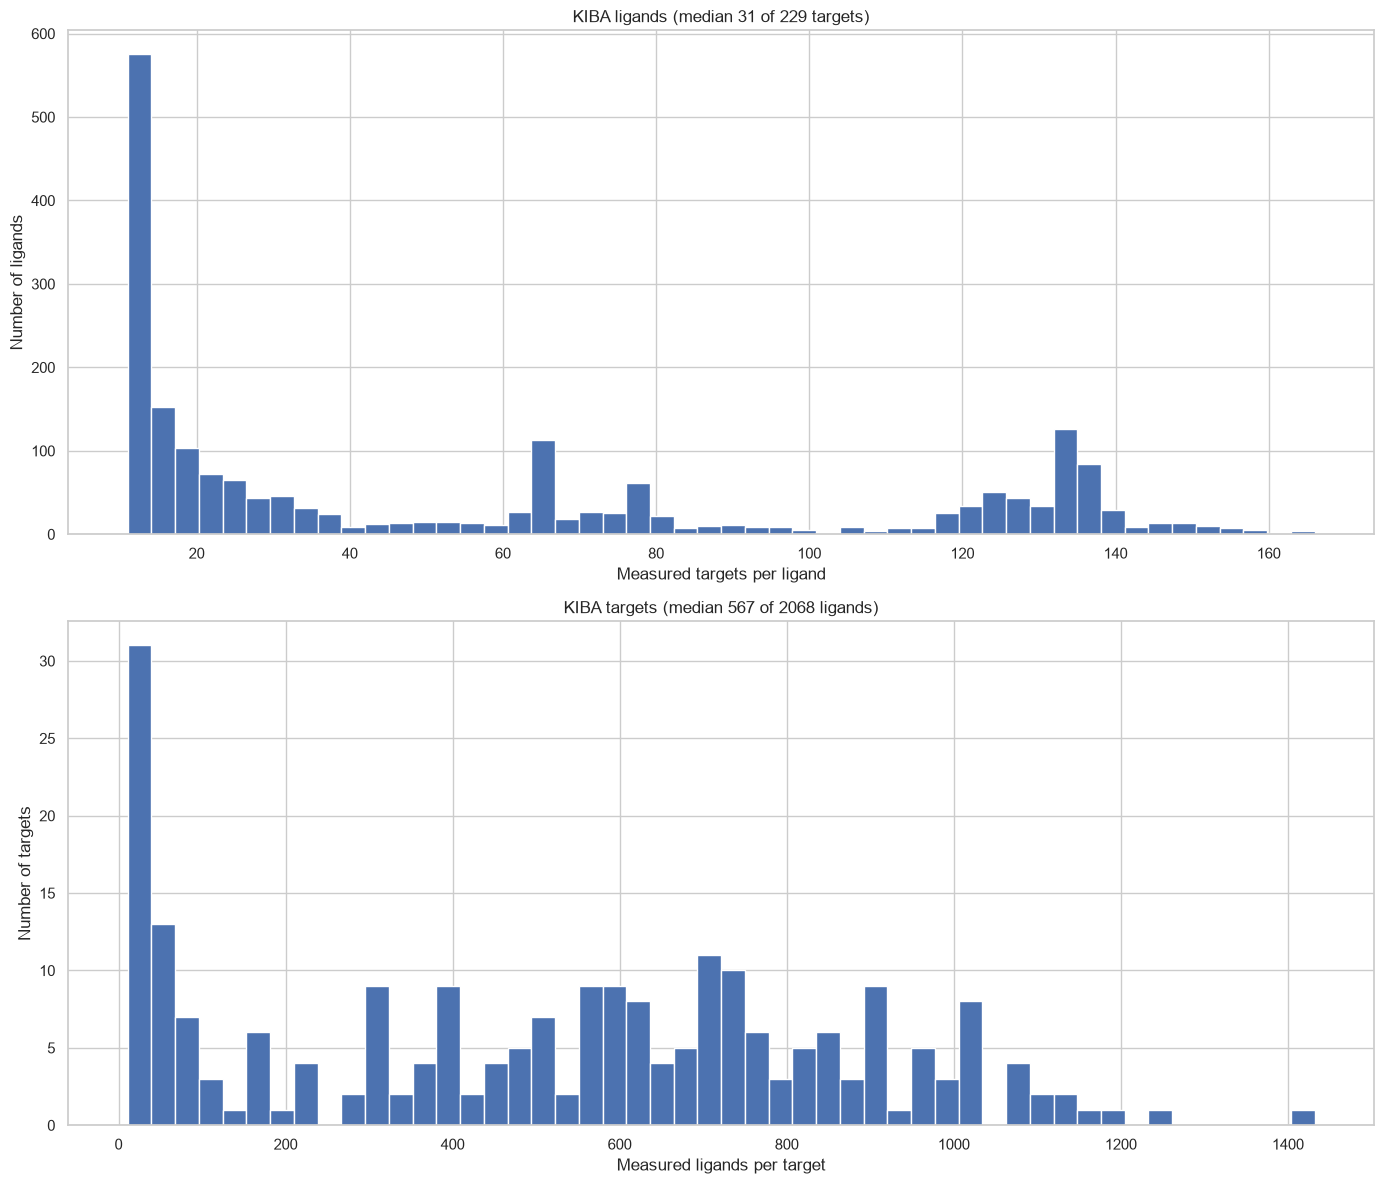

,per ligand,per target
count,2068.0,229.0
mean,56.9,513.8
std,48.8,350.9
min,11.0,11.0
25%,14.0,167.0
50%,31.0,567.0
75%,104.2,771.0
max,166.0,1432.0


In [55]:
lig_counts = kiba_pairs.groupby("ligand_key").size()
tgt_counts = kiba_pairs.groupby("target_key").size()

fig, axes = plt.subplots(2, 1, figsize=(14, 12))
axes[0].hist(lig_counts, bins=50)
axes[0].set_xlabel("Measured targets per ligand")
axes[0].set_ylabel("Number of ligands")
axes[0].set_title(f"KIBA ligands (median {lig_counts.median():.0f} of {kiba_M.shape[1]} targets)")
axes[1].hist(tgt_counts, bins=50)
axes[1].set_xlabel("Measured ligands per target")
axes[1].set_ylabel("Number of targets")
axes[1].set_title(f"KIBA targets (median {tgt_counts.median():.0f} of {kiba_M.shape[0]} ligands)")
plt.tight_layout()
plt.savefig(FIG_DIR / "kiba_observation_counts.png", dpi=200)
plt.show()

pd.DataFrame({"per ligand": lig_counts.describe(), "per target": tgt_counts.describe()}).round(1)

### 4b. Ligand selectivity in DAVIS

For each ligand: the fraction of targets with measurable binding ($\mathrm{p}K_d > 5$) and with strong binding ($\mathrm{p}K_d \geq 7$, e.g. $K_d \leq 100$ nM). Selective ligands bind few targets while promiscuous ones bind many.

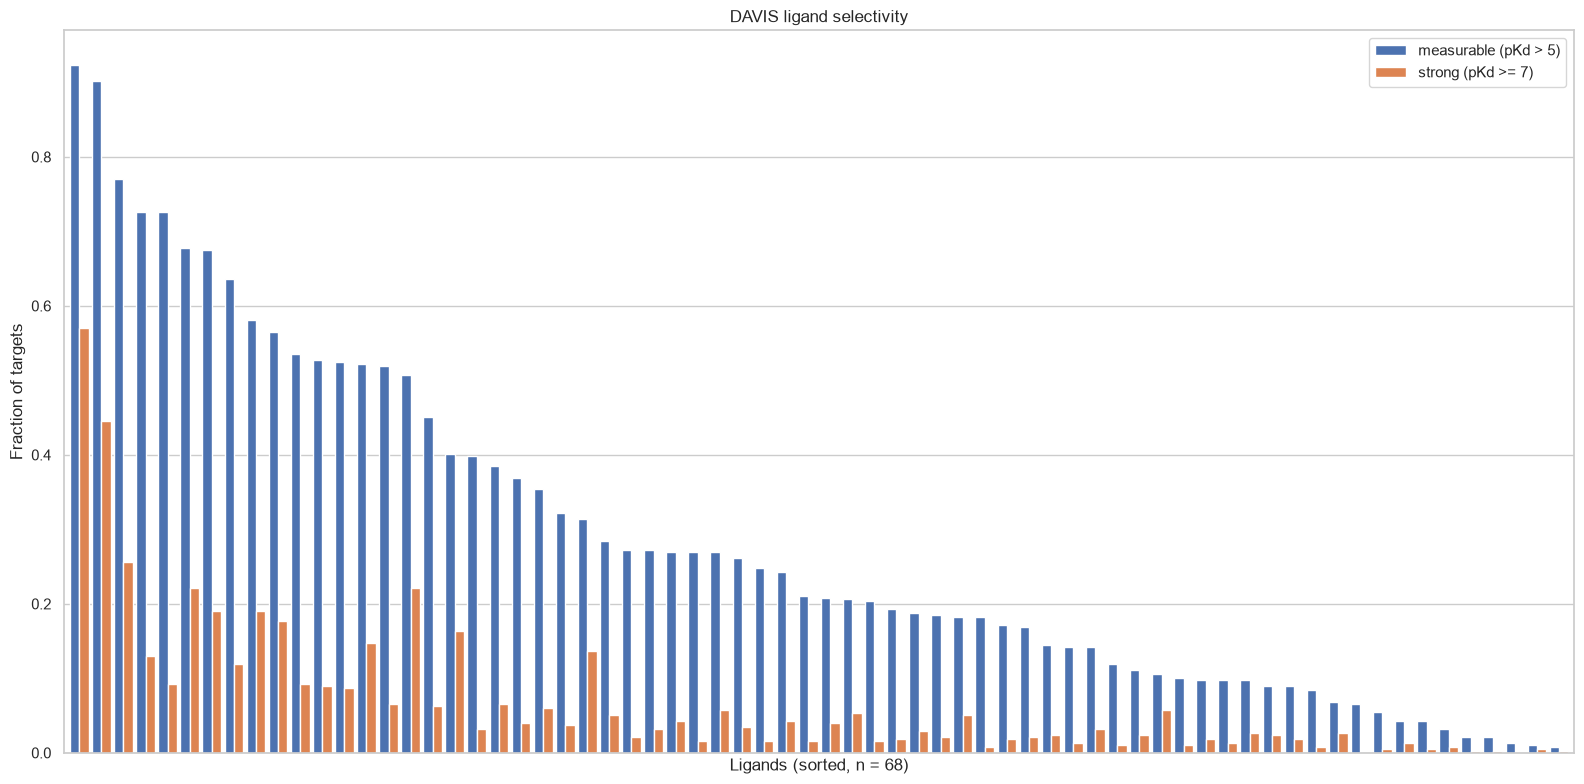

,measurable (pKd > 5),strong (pKd >= 7)
count,68.000,68.000
mean,0.288,0.068
std,0.233,0.099
min,0.008,0.000
25%,0.100,0.016
50%,0.210,0.032
75%,0.414,0.071
max,0.923,0.570


In [56]:
selectivity = pd.DataFrame({
    "measurable (pKd > 5)": (davis_M > DAVIS_LIMIT_PKD).mean(axis=1),
    "strong (pKd >= 7)": (davis_M >= 7).mean(axis=1),
}).sort_values("measurable (pKd > 5)", ascending=False)

ax = selectivity.plot(kind="bar", figsize=(16, 8), width=0.85)
ax.set_xticks([])
ax.set_xlabel(f"Ligands (sorted, n = {len(selectivity)})")
ax.set_ylabel("Fraction of targets")
ax.set_title("DAVIS ligand selectivity")
plt.tight_layout()
plt.savefig(FIG_DIR / "davis_selectivity.png", dpi=200)
plt.show()

selectivity.describe().round(3)

### 4c. Do similar targets have similar binding profiles?

Each target's *binding profile* is its column of scores across ligands. If targets with similar sequences also have correlated profiles, that supports collaborative filtering (Task 2) and suggests that sequence similarity could predict scores for targets with no measurements (Task 3).

Sequence similarities are the ones supplied with each dataset. The DAVIS Smith–Waterman scores are normalised as $s'_{ij} = s_{ij} / \sqrt{s_{ii}\, s_{jj}}$ so they lie in $[0, 1]$. Profiles are compared with Pearson correlation.

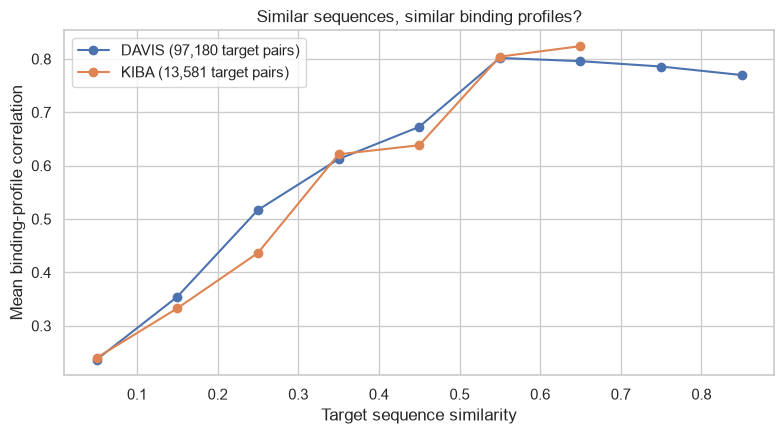

,DAVIS,KIBA
"Spearman(sequence similarity, profile correlation)",0.329,0.252


In [57]:
def load_target_similarity(name, file, normalise=False):
    S = np.genfromtxt(DATA_DIR / name / file)
    if normalise:
        d = np.sqrt(np.diag(S))
        S = S / np.outer(d, d)
    ids = list((davis_proteins if name == "davis" else kiba_proteins).keys())
    return pd.DataFrame(S, index=ids, columns=ids)

def similarity_vs_profile(S, M_original, min_overlap):
    corr = M_original.corr(min_periods=min_overlap)
    iu = np.triu_indices(len(S), k=1)
    df = pd.DataFrame({"sequence_similarity": S.values[iu],
                       "profile_correlation": corr.loc[S.index, S.columns].values[iu]}).dropna()
    df = df[df["sequence_similarity"] < 0.999]     # drop identical sequences (merged duplicates)
    df["similarity_bin"] = pd.cut(df["sequence_similarity"], bins=np.linspace(0, 1, 11))
    return df

davis_orig = pd.DataFrame(9 - np.log10(davis_Y), index=list(davis_ligands), columns=list(davis_proteins))
kiba_orig = pd.DataFrame(kiba_Y, index=list(kiba_ligands), columns=list(kiba_proteins))

davis_sim = similarity_vs_profile(load_target_similarity("davis", "target-target_similarities_WS.txt", normalise=True),
                                  davis_orig, min_overlap=10)
kiba_sim = similarity_vs_profile(load_target_similarity("kiba", "kiba_target_sim.txt"),
                                 kiba_orig, min_overlap=30)

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, df in [("DAVIS", davis_sim), ("KIBA", kiba_sim)]:
    binned = df.groupby("similarity_bin", observed=True)["profile_correlation"].agg(["mean", "count"])
    binned = binned[binned["count"] >= 20]          # skip bins with too few target pairs
    centres = [b.mid for b in binned.index]
    ax.plot(centres, binned["mean"], marker="o", label=f"{name} ({len(df):,} target pairs)")
ax.set_xlabel("Target sequence similarity")
ax.set_ylabel("Mean binding-profile correlation")
ax.set_title("Similar sequences, similar binding profiles?")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "similarity_vs_profile.png", dpi=200)
plt.show()

pd.DataFrame({
    "DAVIS": [davis_sim[["sequence_similarity", "profile_correlation"]].corr(method="spearman").iloc[0, 1]],
    "KIBA": [kiba_sim[["sequence_similarity", "profile_correlation"]].corr(method="spearman").iloc[0, 1]],
}, index=["Spearman(sequence similarity, profile correlation)"]).round(3)